In [150]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from joblib import Parallel, delayed

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC

from scipy.spatial.distance import cdist

from src.gaussian_mixture import GaussianMixtureMAR

### Load breast cancer dataset and split into train/test

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

Xy_train = X_train.copy()
Xy_train['target'] = y_train.values

### Amputation functions (MAR with MNAR contamination)

In [48]:
def build_patterns(columns, pattern_defs):
    """mice::ampute convention: 0 = set to missing, 1 = stays observed."""
    rows, freqs = [], []
    for missing_cols, freq in pattern_defs:
        missing = set(missing_cols)
        rows.append([0 if c in missing else 1 for c in columns])
        freqs.append(freq)
    patterns_df = pd.DataFrame(rows, columns=list(columns))
    return patterns_df, freqs

def r_ampute(df, mech, seed, patterns_df, freq_list):
    """Call mice::ampute on a pandas DataFrame, return a numpy array with NaNs."""
    import rpy2.robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter
    from rpy2.robjects.packages import importr

    mice = importr("mice")   # cached by rpy2, so repeated calls are cheap

    with localconverter(ro.default_converter + pandas2ri.converter):
        r_df = ro.conversion.py2rpy(df)
        r_patterns = ro.conversion.py2rpy(patterns_df)
    r_freq = ro.FloatVector(freq_list)

    ro.r("set.seed")(int(seed))
    res = mice.ampute(r_df, prop=0.999, patterns=r_patterns, freq=r_freq, mech=mech)
    amp = res.rx2("amp")
    with localconverter(ro.default_converter + pandas2ri.converter):
        return ro.conversion.rpy2py(amp).to_numpy(dtype=float)


def mixed_ampute(X, c0, eps, pattern_defs, seed=0):
    rng = np.random.default_rng(seed)
    n = len(X)
    
    patterns_df, freq_list = build_patterns(X.columns, pattern_defs)
    
    complete = rng.random(n) < c0
    mnar = ~complete & (rng.random(n) < eps / (1 - c0))   # gives eps*n MNAR rows on average
    mar = ~complete & ~mnar

    out = X.to_numpy(dtype=float).copy()
    for mask, mech, s in [(mnar, "MNAR", seed), (mar, "MAR", seed + 1)]:
        if mask.sum() == 0:
            continue
        out[mask] = r_ampute(X[mask], mech, s, patterns_df, freq_list)

    X_amp = pd.DataFrame(out, columns=X.columns, index=X.index)
    return X_amp, complete, mnar, mar

### Privacy metric NNDR 5%
(see paper by Julie)

In [49]:
def second_smallest(lst):
    first, second = lst[0], lst[1]

    if first> second:
        first, second = second, first

    for num in lst[2:]:
        if num < first:  
            second, first = first, num  # Mettre à jour les 2 plus petits
        elif num < second or second == first:  
            second = num  # Mettre à jour seulement le deuxième plus petit
    return first, second

def NNDR(df_synthetic, df_true,all=False ):
    scaler = StandardScaler().fit(df_true)
    df_true_norm = pd.DataFrame(scaler.transform(df_true))
    df_sythetic_norm = pd.DataFrame(scaler.transform(df_synthetic))

    distances = cdist(df_true_norm.values, df_sythetic_norm.values, metric="euclidean")
    nndr =[]
    dcr =[]
    for i in range(len(df_true_norm)):
        first, second = second_smallest(distances[i])
        nndr.append(first/second)
        dcr.append(first)
    if all==True :
        return ([np.percentile(dcr,5),np.percentile(dcr,10), np.percentile(dcr,25), np.percentile(dcr,50), np.percentile(dcr,75),np.percentile(dcr,90), np.percentile(dcr,95) ], 
        [np.percentile(nndr,5),np.percentile(nndr,10), np.percentile(nndr,25), np.percentile(nndr,50), np.percentile(nndr,75),np.percentile(nndr,90), np.percentile(nndr,95)]) 
    else :
        return np.percentile(dcr,5),np.percentile(nndr,5)

## 1. Prediction task: Classification

### Worker function for classification (ampute, impute/generate, fit RF, evaluate on test)

In [50]:
def ampute_impute_fit_test(Xy_train, c0, eps, pattern_defs, X_test, y_test, B=50, seed=0):
    ### AMPUTE
    Xy_train_amp, complete, mnar, mar = mixed_ampute(Xy_train, c0=c0, eps=eps, seed=seed, pattern_defs=pattern_defs)

    ### FIT GMM
    k_range = (1,500) # ks to choose from
    crit = 'bic' # criterion for choosing k
    ct = 'diag' # covariance structure
    n_inits = 20
    
    Xm = torch.tensor(Xy_train_amp.values, dtype=torch.float32)
    X = torch.nan_to_num(Xm, nan=0.0) # input to GMM
    M_np = (Xy_train_amp.notna()).astype(int).values
    M = torch.tensor(M_np, dtype=torch.float32)
    gmm = GaussianMixtureMAR(k_range=k_range, 
                             criterion=crit,
                             cov_type=ct, 
                             n_init=n_inits)
    gmm.fit(X, M)

    ### SAMPLE COMPLETE DATA AND COMPUTE METRICS
    results = []
    for i in range(B):
        for method in ['gen', 'imp']:
            if method == 'gen':
                Xy_train_new = gmm.sample(len(Xy_train))[0]
            else:
                Xy_train_new = gmm.impute(X, M)
            Xy_train_new_df = pd.DataFrame(Xy_train_new.detach().numpy())
            Xy_train_new_df.columns = Xy_train.columns
            X_train_new = Xy_train_new_df.loc[:, Xy_train_new_df.columns != 'target']
            y_train_new = (Xy_train_new_df['target'] > 0.5).astype(int)
        
            # Fit classification RF
            clf = RandomForestClassifier()
            clf.fit(X_train_new, y_train_new)
            y_pred_full = clf.predict(X_test)
            clf_accu_synt = accuracy_score(y_test, y_pred_full)
    
            # Determine privacy metric
            dcr, nndr = NNDR(Xy_train_new_df, Xy_train)
            
            results.append({"eps": eps,
                            "method": method,
                            "clf_accu": clf_accu_synt,
                            "nndr": nndr})
    return results

### Missingness patterns and other params

In [55]:
eps_vals = np.arange(0, 1.1, 0.1)
c0 = 0.1

cols = list(Xy_train.columns)

# pattern definitions: columns that get set to missing, plus frequency
pattern_defs = [
    (["mean radius", "mean perimeter", "mean area"], 0.15),
    (["mean compactness", "mean concavity", "mean concave points"], 0.15),
    ([c for c in cols if c.startswith("worst")], 0.20),
    ([c for c in cols if c.endswith("error")], 0.20),
    ([c for c in cols if "radius" in c] + [c for c in cols if "area" in c] + [c for c in cols if "perimeter" in c], 0.2),
    (["target"], 0.1)
]

In [47]:
# average missingness
avg_mis = (1-c0)*np.sum([(len(p[0])/len(cols))*p[1] for p in pattern_defs])
print(f"Average missingness: {avg_mis*100:.2f}%")

Average missingness: 19.74%


### Start parellel runs

In [56]:
results = Parallel(n_jobs=-1)( 
    delayed(ampute_impute_fit_test)(Xy_train, c0, eps, pattern_defs, X_test, y_test) 
    for eps in eps_vals)

### Fit random forest to complete training dataset

In [58]:
clf_full = RandomForestClassifier()
clf_full.fit(X_train, y_train)
y_pred_full = clf_full.predict(X_test)
clf_full_accu = accuracy_score(y_test, y_pred_full)

### Plot results

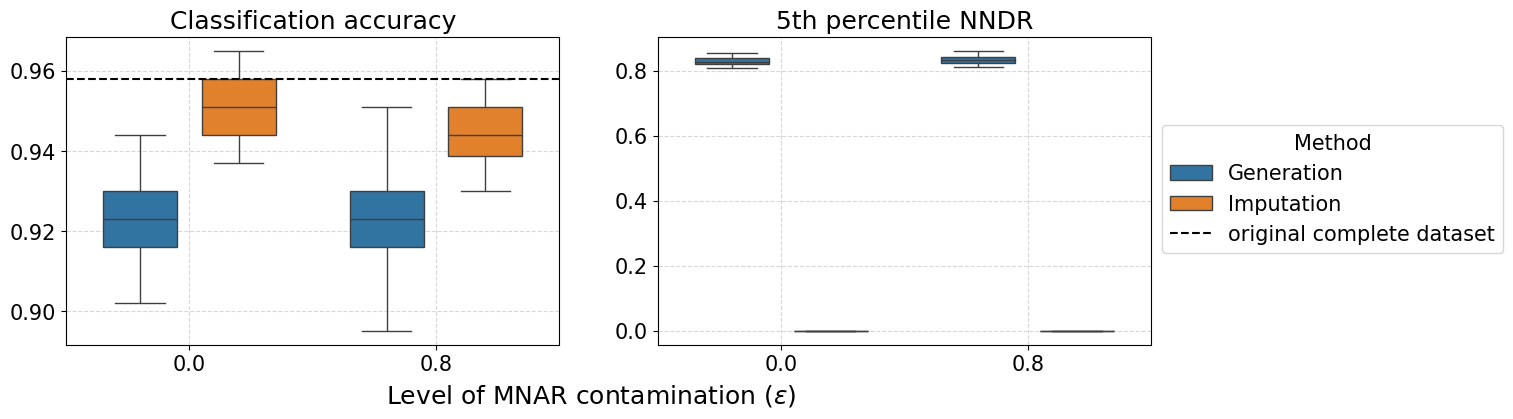

In [142]:
plt.rcParams.update({'font.size': 15})

## Decide which eps values to plot
# plot_df = pd.DataFrame([r for res in results for r in res])
plot_df = pd.DataFrame(results[0] + results[8])
plot_df["eps"] = plot_df["eps"].round(2)
plot_df["method"] = plot_df["method"].map({"gen": "Generation", "imp": "Imputation"})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, label in [(axes[0], "clf_accu", "Classification accuracy"), (axes[1], "nndr", "5th percentile NNDR")]:
    sns.boxplot(data=plot_df, x="eps", y=col, hue="method", ax=ax, patch_artist=True, showfliers=False, widths=0.3)
    if col == "clf_accu":
        # sns.boxplot(data=plot_df, x="eps", y=col, hue="method", ax=ax, patch_artist=True, showfliers=False, widths=0.3)
        ax.axhline(clf_full_accu, color="black", linestyle="--", label='original complete dataset')
    # else:
    #     sns.boxplot(data=plot_df[plot_df["method"] == 'Generation'], x="eps", y=col, ax=ax, patch_artist=True, showfliers=False, widths=0.3)

    ax.grid(True, linestyle='--', alpha=0.5)    
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(f"{label}")
    ax.set_xlabel("")
    ax.legend(title="")
    # plt.tight_layout()
    # plt.show()

# grab handles/labels before removing the per-axis legends
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
fig.legend(handles, labels, title="Method",
           loc="center left", bbox_to_anchor=(0.9, 0.5))

fig.supxlabel(r"Level of MNAR contamination ($\varepsilon$)", y=-0.05)
plt.savefig("cancer_classification.png", dpi=150, bbox_inches="tight")

In [37]:
# plt.boxplot(np.array(results)[:,:,0].T)
# plt.xticks(range(1, len(eps_vals) + 1), np.round(eps_vals, decimals=1))
# plt.axhline(clf_full_accu)
# plt.xlabel("MNAR contamination")
# plt.ylabel("Accuracy of RF classification")
# plt.show()

# plt.boxplot(np.array(results)[:,:,1].T)
# plt.xticks(range(1, len(eps_vals) + 1), np.round(eps_vals, decimals=1))
# # plt.axhline(clf_full_accu)
# plt.xlabel("MNAR contamination")
# plt.ylabel("NNDR 5% (privacy metric)")

## 2. Exploratory data analysis: PCA

### Worker function for classification (ampute, impute/generate, fit RF, evaluate on test)

In [193]:
def pca_linearsep(X_train, y_train, X_test, y_test):
    # Perform PCA
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    pca = PCA(n_components=2)
    PC_pca = pca.fit_transform(X_train_scaled)
    
    # Fit linear SVC on the 2 principal components
    svc = LinearSVC(C=1.0, max_iter=10000)
    svc.fit(PC_pca, y_train)
    
    # Accuracy
    PC_test = pca.transform(scaler.transform(X_test))
    acc = accuracy_score(y_test, svc.predict(PC_test))

    w = svc.coef_[0]
    b = svc.intercept_[0]
    x_vals = np.linspace(PC_pca[:, 0].min(), PC_pca[:, 0].max(), 200)
    y_vals = -(w[0] * x_vals + b) / w[1]

    return PC_pca, -w[0]/w[1], -b/w[1], acc

In [194]:
def ampute_impute_pca(Xy_train, c0, eps, pattern_defs, X_test, y_test, method='gmm_impute', B=5, seed=0):
    ### AMPUTE
    Xy_train_amp, complete, mnar, mar = mixed_ampute(Xy_train, c0=c0, eps=eps, seed=seed, pattern_defs=pattern_defs)

    if method == 'gmm_impute':
        X_train = Xy_train_amp.loc[:,Xy_train_amp.columns != 'target']
        y_train_new = Xy_train_amp['target'] #> 0.5
        Xm = torch.tensor(X_train.values, dtype=torch.float32)
        M_np = (X_train.notna()).astype(int).values
        M = torch.tensor(M_np, dtype=torch.float32)
    else:
        Xm = torch.tensor(Xy_train_amp.values, dtype=torch.float32)
        M_np = (Xy_train_amp.notna()).astype(int).values
        M = torch.tensor(M_np, dtype=torch.float32)

    ### FIT GMM
    if method == 'gmm_sample' or method == 'gmm_impute':
        k_range = (1,500) # ks to choose from
        crit = 'bic' # criterion for choosing k
        ct = 'diag' # covariance structure
        n_inits = 20
        
        X = torch.nan_to_num(Xm, nan=0.0) # input to GMM
        gmm = GaussianMixtureMAR(k_range=k_range, 
                                 criterion=crit,
                                 cov_type=ct, 
                                 n_init=n_inits)
        gmm.fit(X, M)        
    elif method == 'flowgem':
        # Standardize X0
        col_mean = torch.nanmean(Xm, dim=0)
        col_std = torch.nanmean((Xm - col_mean) ** 2, dim=0) ** 0.5
    elif method == 'mice':
        pass
    else:
        raise NameError(f"Wrong method specification: {method}. Only 'gmm' or 'flowgem' are possible.")

    ### SAMPLE COMPLETE DATA AND FIT RF
    results = []
    for i in range(B):
        if method == 'gmm_impute':
            X_train_new = gmm.impute(X, M)
            X_train_new_df = pd.DataFrame(X_train_new.detach().numpy())
            X_train_new_df.columns = X_train.columns
            y_train_new = y_train
        else:
            if method == 'gmm_sample':
                # Sample from GMM
                Xy_train_new = gmm.sample(len(Xy_train))[0]
            elif method == 'flowgem':
                # Use mice imputation with 10 iterations as X0
                imputer = Imputers().get("mice", max_iter=10, random_state=i)
                df = imputer.fit_transform(Xy_train_amp)
                X0_tensor = torch.tensor(df.values, dtype=torch.float64)
                # Standardize X0
                X0_std = (X0_tensor - col_mean) / col_std
                # Run flowgem and undo standardization
                Xhat = sample_flowgem(X0_std, X0_std, M, T=1000, eta=0.01, grad_tol=0.01)[-1]
                Xy_train_new = torch.tensor(Xhat, dtype=torch.float64) * col_std + col_mean
            elif method == 'mice':
                imputer = Imputers().get("mice", max_iter=10, random_state=i)
                df = imputer.fit_transform(Xy_train_amp)
                Xy_train_new = torch.tensor(df.values, dtype=torch.float64)
                
            Xy_train_new_df = pd.DataFrame(Xy_train_new.detach().numpy())
            Xy_train_new_df.columns = Xy_train.columns
            X_train_new = Xy_train_new_df.loc[:,Xy_train_new_df.columns != 'target']
            y_train_new = Xy_train_new_df['target'] > 0.5

        PC_pca, slope, intercept, acc = pca_linearsep(X_train_new, y_train_new, X_test, y_test)
        
        results.append({"pcs": PC_pca,
                        "labels": y_train_new.to_numpy(),
                        "slope": slope,
                        "intercept": intercept,
                        "acc": acc})
    return np.array(results)

### Missingness patterns and other params

In [195]:
eps_vals = np.arange(0, 1.1, 0.1)
c0 = 0.1

missingness_in_y = False

# pattern definitions: columns that get set to missing, plus frequency
if missingness_in_y:
    cols = list(Xy_train.columns)
    pattern_defs = [
        (["mean radius", "mean perimeter", "mean area"], 0.15),
        (["mean compactness", "mean concavity", "mean concave points"], 0.15),
        ([c for c in cols if c.startswith("worst")], 0.20),
        ([c for c in cols if c.endswith("error")], 0.20),
        ([c for c in cols if "radius" in c] + [c for c in cols if "area" in c] + [c for c in cols if "perimeter" in c], 0.2),
        (["target"], 0.1)
    ]
else:
    cols = list(X_train.columns)
    pattern_defs = [
        (["mean radius", "mean perimeter", "mean area"], 0.2),
        (["mean compactness", "mean concavity", "mean concave points"], 0.2),
        ([c for c in cols if c.startswith("worst")], 0.20),
        ([c for c in cols if c.endswith("error")], 0.20),
        ([c for c in cols if "radius" in c] + [c for c in cols if "area" in c] + [c for c in cols if "perimeter" in c], 0.2)
    ]
    # pattern_defs = [
    #     ([c for c in cols if c.startswith("worst")], 0.1),
    #     ([c for c in cols if c.endswith("error")], 0.1),
    #     ([c for c in cols if "radius" in c] + [c for c in cols if "area" in c] + [c for c in cols if "perimeter" in c], 0.4),
    #     ([c for c in cols if "compactness" in c] + [c for c in cols if "concavity" in c] + [c for c in cols if "concave" in c], 0.4)
    # ]

In [196]:
# average missingness
avg_mis = (1-c0)*np.sum([(len(p[0])/len(cols))*p[1] for p in pattern_defs])
print(f"Average missingness: {avg_mis*100:.2f}%")

Average missingness: 21.00%


### Start parallel runs

In [ ]:
results = Parallel(n_jobs=-1)( 
    delayed(ampute_impute_pca)(Xy_train, c0, eps, pattern_defs, X_test, y_test, method='gmm_impute') 
    for eps in eps_vals)

### Compute PCA for full dataset

In [ ]:
PC_pca, slope, intercept, acc_full = pca_linearsep(X_train, y_train, X_test, y_test)

### Plot results

In [186]:
def plot_pca_svc(ax, pretitle, PC_pca, labels, slope, intercept, acc):
    xlims = [-7, 15]
    ylims = [-12, 14]

    x_vals = np.array(xlims)
    y_vals = slope * x_vals + intercept
    
    ax.scatter(PC_pca[labels == 0, 0], PC_pca[labels == 0, 1], color='#DC3220', label='Malignant')
    ax.scatter(PC_pca[labels == 1, 0], PC_pca[labels == 1, 1], color='#005AB5', label='Benign')
    ax.plot(x_vals, y_vals, color='black', linestyle='--', label=f'Linear SVM') # ({slope:.2f}, {intercept:.2f})')
    ax.set_xlim(xlims[0], xlims[1]) #(PC_pca[:, 0].min() - 0.5, PC_pca[:, 0].max() + 0.5)
    ax.set_ylim(ylims[0], ylims[1]) #(PC_pca[:, 1].min() - 0.5, PC_pca[:, 1].max() + 0.5)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(f'Acc: {acc*100:.2f}%') #{pretitle} --- 
    ax.legend()

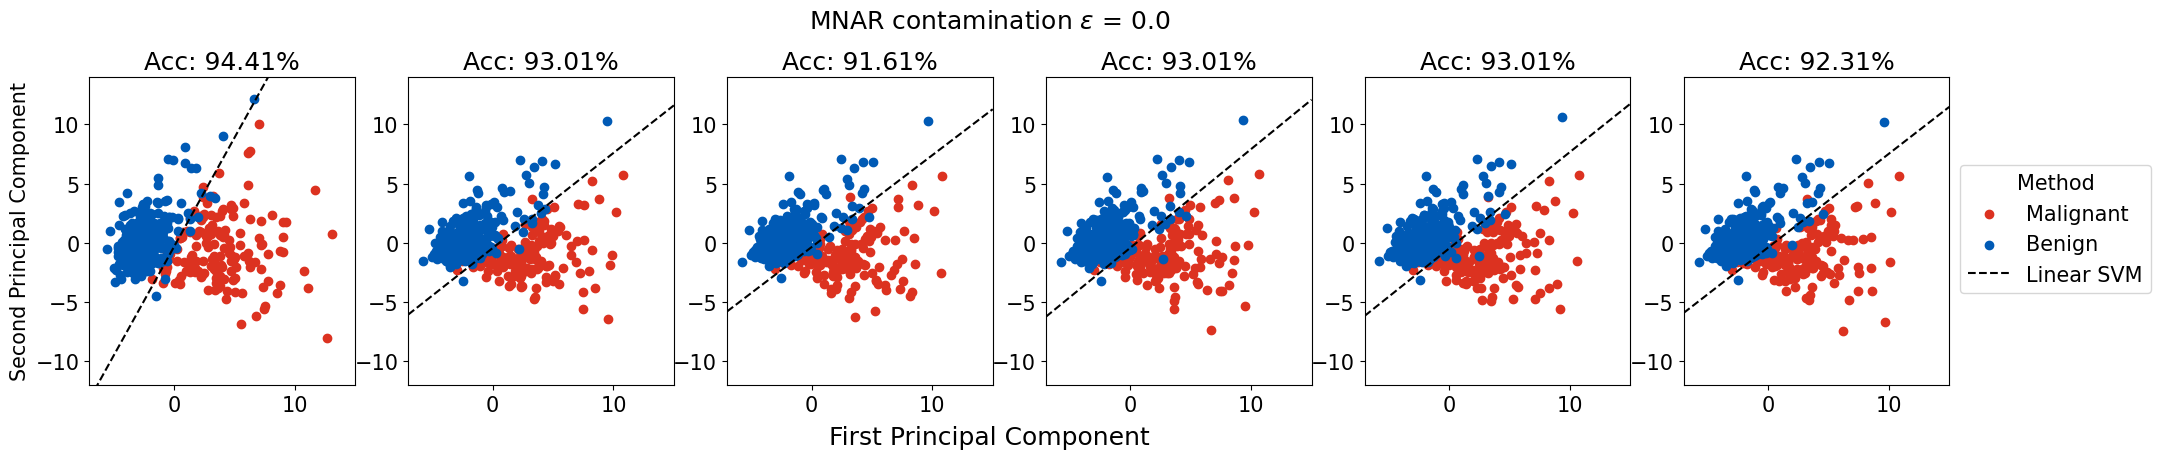

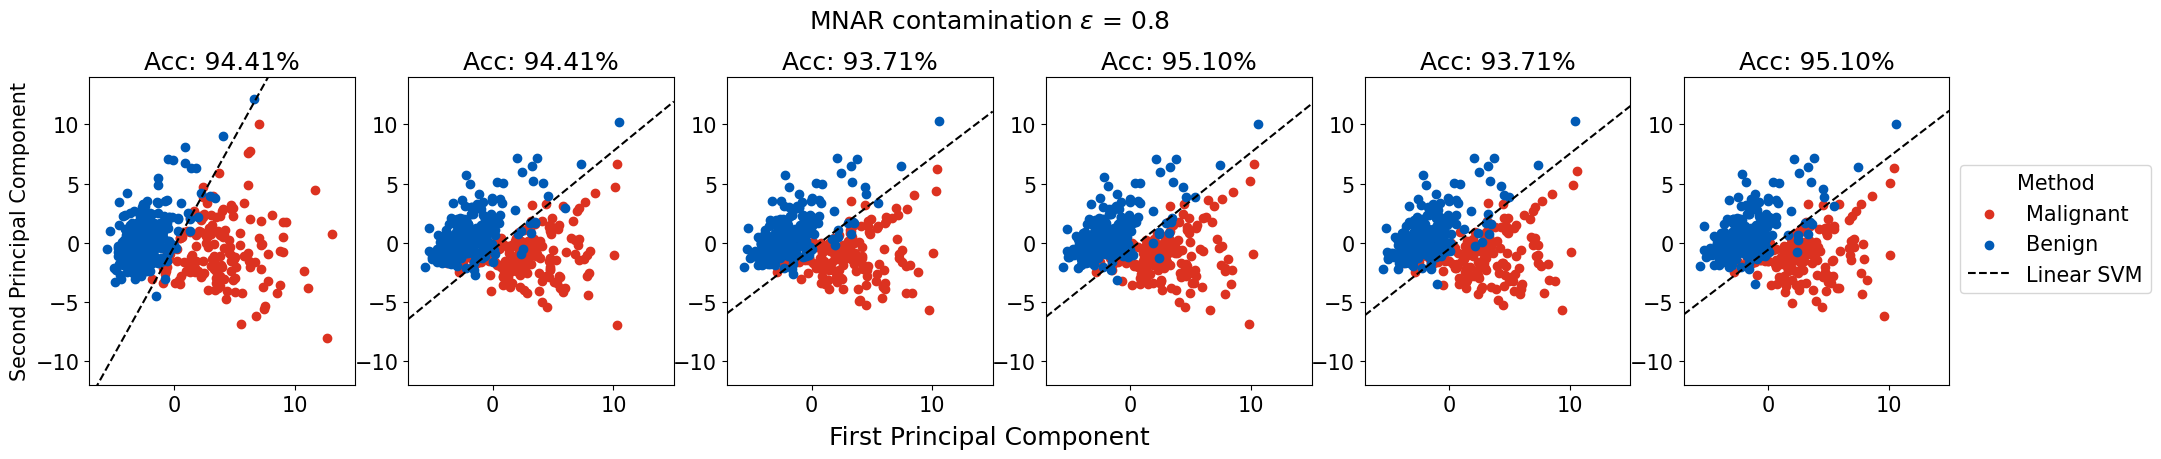

In [191]:
for i, eps in enumerate(eps_vals): 
    if eps not in [0.0, 0.8]:
        continue
    fig, axes = plt.subplots(1, len(results[i]) + 1, figsize=(4*(len(results[i]) + 1), 4))
    # fig.set_title(f'Generated datasets with eps={eps}')
    plot_pca_svc(axes[0], "Full data", PC_pca, y_train, slope, intercept, acc_full)
    for j, res in enumerate(results[i]):        
        plot_pca_svc(axes[j+1], f"eps = {eps.round(2)}", res['pcs'], res['labels'], res['slope'], res['intercept'], res['acc'])
    axes[0].set_ylabel('Second Principal Component')
    fig.supxlabel("First Principal Component", y=-0.05)
    fig.suptitle(rf"MNAR contamination $\varepsilon$ = {eps}", y=1.05)

    # grab handles/labels before removing the per-axis legends
    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, title="Method",
               loc="center left", bbox_to_anchor=(0.9, 0.5))
    
    plt.savefig(f"cancer_pca_eps={eps.round(2)}.png", dpi=150, bbox_inches="tight")
    plt.show()